In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os,cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from keras.utils import np_utils

In [ ]:
data_path='/content/drive/MyDrive/RASHI/DATA/cassava-disease/train' # Give your path here.
data_dir_list = ['0', '1', '2', '3', '4']
img_data_list=[]
labels = []

for dataset in data_dir_list:
    img_list=os.listdir(data_path+'/'+ dataset)
    print ('Loaded the images of dataset-'+'{}\n'.format(dataset))
    for img in img_list:
        input_img=cv2.imread(data_path + '/'+ dataset + '/'+ img )
        # input_img=cv2.IMREAD_GRAYSCALE
        labels.append(dataset)
        input_img_resize=cv2.resize(input_img,(128, 128))  # Here, Write your image size.
        img_data_list.append(input_img_resize)

label=np.array(labels)
data = np.array(img_data_list)
# print(data)
data = data.astype('float32')
data = data/255
data.shape

Loaded the images of dataset-0

Loaded the images of dataset-1

Loaded the images of dataset-2

Loaded the images of dataset-3

Loaded the images of dataset-4



(5894, 128, 128, 3)

In [ ]:
num_classes = 5 # Number of classes in your dataset
Y = np_utils.to_categorical(label, num_classes)
x,y = shuffle(data,Y, random_state=2)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.1, random_state = 2)
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (5304, 128, 128, 3)
Shape of X_test: (590, 128, 128, 3)
Shape of y_train: (5304, 5)
Shape of y_test: (590, 5)


In [ ]:
import numpy as np
import pandas as pd
x = X_train.reshape(5304, -1)
np.savetxt('/content/drive/MyDrive/RASHI/CASAVA/Casava_X_train.csv', x, delimiter = ",")

q =  np.argmax(y_train, axis =1).reshape(5304, -1)
np.save('q.npy', q)
k = np.load('q.npy')
np.savetxt("/content/drive/MyDrive/RASHI/CASAVA/Casava_y_train.csv", k,  delimiter = ",")

In [ ]:
X_train = X_train.reshape(-1,128,128, 3)
X_test = X_test.reshape(-1, 128, 128, 3)

In [ ]:
from keras.layers import Conv2D, GlobalAveragePooling2D, Reshape, Dense, Multiply, Add

def eca_module(input_tensor, gamma=2, b=1):
    channels = input_tensor.shape[-1]
    print(channels)

    squeeze = GlobalAveragePooling2D()(input_tensor)
    excitation = Dense(units=channels // gamma)(squeeze)
    excitation = Activation('relu')(excitation)
    excitation = Dense(units=channels)(excitation)
    excitation = Activation('sigmoid')(excitation)
    excitation = Reshape((1, 1, channels))(excitation)

    scale = Multiply()([input_tensor, excitation])

    output = Add()([scale, input_tensor])
    return output

In [ ]:
def residual_csa_module(input_tensor, reduction_ratio=16):
    channels = input_tensor.shape[-1]

    # Convolutional layer for feature extraction
    conv1 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    conv2 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(conv1)
    conv3 = Conv2D(filters=channels, kernel_size=(1, 1), padding='same', activation='relu')(conv2)

    # Spatial attention mechanism
    attention_map = Conv2D(filters=1, kernel_size=(1, 1), padding='same', activation='sigmoid')(conv3)

    # Multiply attention map with input tensor
    attention = Multiply()([attention_map, input_tensor])

    # Residual connection
    output = Add()([attention, input_tensor])

    return output

In [ ]:
from keras.layers import Conv2D, SeparableConv2D, Concatenate, AveragePooling2D

def inception_block(input_tensor, filters):
    # Path 1: 1x1 Convolution
    path1 = Conv2D(filters[0], kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)

    # Path 2: 1x1 Convolution followed by 3x3 Depthwise Separable Convolution
    path2 = Conv2D(filters[1], kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    path2 = SeparableConv2D(filters[2], kernel_size=(3, 3), padding='same', activation='relu')(path2)

    # Path 3: 1x1 Convolution followed by two 3x3 Depthwise Separable Convolutions
    path3 = Conv2D(filters[3], kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    path3 = SeparableConv2D(filters[4], kernel_size=(3, 3), padding='same', activation='relu')(path3)
    path3 = SeparableConv2D(filters[5], kernel_size=(3, 3), padding='same', activation='relu')(path3)

    # Path 4: 3x3 Average Pooling followed by 1x1 Convolution
    path4 = AveragePooling2D(pool_size=(3, 3), strides=(1, 1), padding='same')(input_tensor)
    path4 = Conv2D(filters[6], kernel_size=(1, 1), padding='same', activation='relu')(path4)

    # Concatenate the paths
    output_tensor = Concatenate(axis=-1)([path1, path2, path3, path4])

    return output_tensor

In [ ]:
import keras
from keras.applications import EfficientNetB0, ResNet50, VGG16, InceptionV3
from keras.layers import Dense, GlobalAveragePooling2D, Conv2D, Flatten, Add, Activation, Input, MaxPooling2D
from tensorflow.keras.optimizers import RMSprop, Adam, SGD
from tensorflow.keras import regularizers
from keras.models import Model

# base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
# for layer in base_model.layers:
#     layer.trainable = False

# x = base_model.output
input = Input((128, 128, 3))
x = Conv2D(filters=64, kernel_size=(3, 3), activation='relu')(input)
inception_block1 = inception_block(x, filters=[16, 32, 64, 32, 64, 128, 32])
x1 = Conv2D(filters=64, kernel_size=(3, 3), padding = 'same', activation='relu')(inception_block1)
x = Add()([x, x1])
x = Conv2D(filters=128, kernel_size=(3, 3), activation='relu')(x)
x = MaxPooling2D()(x)

# inception_block1 = inception_block(x, filters=[16, 32, 64, 32, 64, 128, 32])
# x = Conv2D(filters=256, kernel_size=(3, 3), activation='relu')(inception_block1)
# x = Conv2D(filters=128, kernel_size=(3, 3), activation='relu')(x)
# x = MaxPooling2D()(x)

eca_module1 = eca_module(x)
res_csa_module1 = residual_csa_module(x)

x = Add()([x, eca_module1, res_csa_module1])
x = Conv2D(filters=256, kernel_size=(3, 3), activation='relu')(x)

x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dense(128, activation='relu')(x)
# Add a fully connected layer for classification
output = Dense(5, activation='softmax')(x)

# Create the model
model = Model(inputs=input, outputs=output)

# Compile the model
# optimizer = Adam(learning_rate=0.0001, weight_decay = 0.99)
# sgd = SGD(learning_rate=0.001, momentum=0.9)
model.compile(optimizer= 'adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Print the model summary
model.summary()

128
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 128, 128, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 126, 126, 64  1792        ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_3 (Conv2D)              (None, 126, 126, 32  2080        ['conv2d[0][0]']                 
                                )                                                         

In [ ]:
# from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
# early_stopping = EarlyStopping(
#                               patience=10,
#                               min_delta=0.001,
#                               monitor="val_loss",
#                               restore_best_weights=True
#                               )
# # Define the model checkpoint callback to save the best weights
# checkpoint = ModelCheckpoint('/content/drive/MyDrive/RASHI/best_Plant_weights.h5', monitor='val_loss', save_best_only=True)

# history = model.fit( X_train, y_train, batch_size = 16, epochs = 100,
#                     validation_data = (X_test , y_test), callbacks=[early_stopping, checkpoint], verbose =1)

Epoch 1/100
332/332 [==============================] - 71s 171ms/step - loss: 1.3493 - accuracy: 0.4644 - val_loss: 1.3166 - val_accuracy: 0.4763
Epoch 2/100
332/332 [==============================] - 50s 151ms/step - loss: 1.2033 - accuracy: 0.5451 - val_loss: 1.1605 - val_accuracy: 0.5729
Epoch 3/100
332/332 [==============================] - 49s 148ms/step - loss: 1.1223 - accuracy: 0.5850 - val_loss: 1.1735 - val_accuracy: 0.5610
Epoch 4/100
332/332 [==============================] - 49s 148ms/step - loss: 1.0859 - accuracy: 0.6022 - val_loss: 1.1287 - val_accuracy: 0.5949
Epoch 5/100
332/332 [==============================] - 49s 148ms/step - loss: 1.0798 - accuracy: 0.6018 - val_loss: 1.1684 - val_accuracy: 0.5661
Epoch 6/100
332/332 [==============================] - 49s 148ms/step - loss: 1.0626 - accuracy: 0.6152 - val_loss: 1.1058 - val_accuracy: 0.6000
Epoch 7/100
332/332 [==============================] - 50s 151ms/step - loss: 1.0338 - accuracy: 0.6227 - val_loss: 1.0888 -

<Figure size 640x480 with 0 Axes>

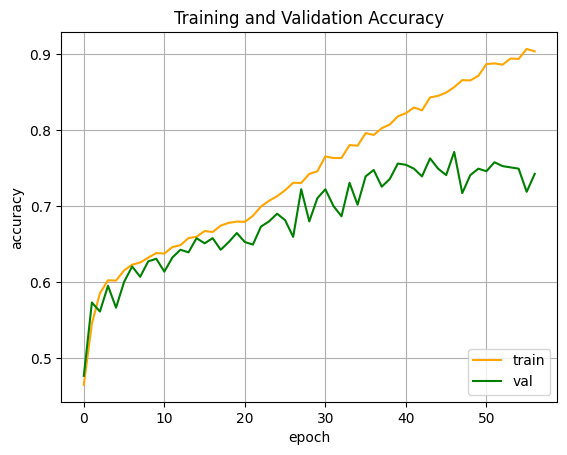

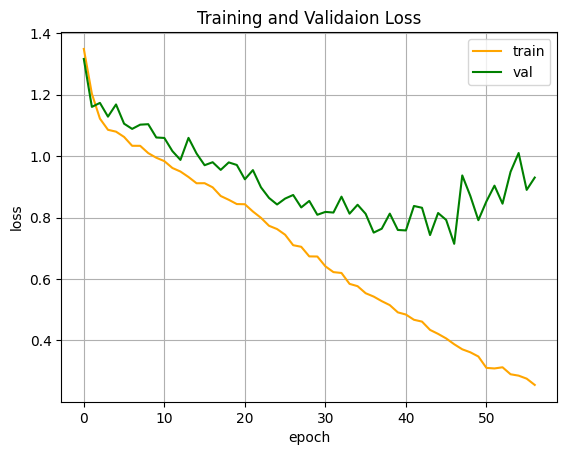

<Figure size 640x480 with 0 Axes>

In [ ]:
# import matplotlib.image as mpimg
# import matplotlib.pyplot as plt

# acc = history.history['accuracy']
# val_acc = history.history['val_accuracy']
# loss = history.history['loss']
# val_loss = history.history['val_loss']

# epochs = range(len(acc))

# plt.plot(epochs, acc, 'orange')
# plt.plot(epochs, val_acc, 'g')
# plt.title('Training and Validation Accuracy')
# plt.ylabel('accuracy')
# plt.xlabel('epoch')
# plt.legend(['train', 'val'], loc='lower right')
# plt.grid()
# plt.figure()

# plt.plot(epochs, loss, 'orange')
# plt.plot(epochs, val_loss, 'g')
# plt.ylabel('loss')
# plt.xlabel('epoch')
# plt.legend(['train', 'val'], loc='upper right')
# plt.title('Training and Validaion Loss')
# plt.grid()
# plt.figure()

#**Loading the Model**

In [ ]:
import keras
model = keras.models.load_model('/content/drive/MyDrive/RASHI/best_Plant_weights.h5')

In [ ]:
# Predicting the Test set results
pred = model.predict(X_test)
print("Y_pred:", pred)
print("*****************")
y_pred = np.argmax(pred, axis = 1)
print("Y_pred:", y_pred)
print("*****************")
print("Y_test:", y_test)
y_true = np.argmax(y_test, axis = 1)
print("*****************")
print("Y_test:", y_true)

19/19 [==============================] - 13s 142ms/step
Y_pred: [[5.7344505e-04 3.8609938e-03 3.4725307e-03 9.9208236e-01 1.0698080e-05]
 [8.3874643e-02 8.4259081e-01 2.0451214e-02 5.0842017e-02 2.2413419e-03]
 [7.9129146e-05 2.5808287e-01 1.1429798e-01 6.2753987e-01 1.1620103e-07]
 ...
 [2.2471270e-02 9.7576421e-01 1.5513336e-03 1.0150599e-04 1.1167577e-04]
 [1.1853221e-02 7.2756010e-01 1.7657124e-01 8.4009819e-02 5.6734102e-06]
 [3.0461773e-03 3.1004569e-03 4.3872697e-03 9.8743886e-01 2.0272553e-03]]
*****************
Y_pred: [3 1 3 3 3 3 2 3 1 3 3 3 0 3 3 0 1 3 3 0 2 3 3 0 3 1 3 1 1 1 3 3 3 0 3 1 3
 2 3 3 3 3 3 3 4 3 1 1 1 1 1 2 0 1 4 1 1 3 2 3 2 3 3 0 3 1 3 3 2 3 1 2 1 3
 3 3 2 0 4 4 3 4 3 2 3 3 3 3 3 3 0 1 4 1 3 1 1 1 2 3 3 0 3 1 3 1 3 3 3 1 3
 1 1 3 0 2 3 1 0 1 3 0 1 1 1 2 3 1 3 1 3 3 3 3 3 1 1 1 1 4 3 4 1 1 3 4 4 3
 3 3 2 3 3 1 1 3 3 3 2 2 1 3 3 1 0 0 1 2 3 3 3 1 1 3 1 1 1 2 0 3 2 3 4 4 3
 2 3 4 3 1 1 4 1 0 3 4 3 1 3 1 3 1 2 3 3 1 3 3 3 1 3 0 3 3 2 3 1 2 0 2 3 3
 2 3 3 1 3 4 1 3

#**Confusion Matrix**

In [ ]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
target_names = ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']

Text(0.5, 23.52222222222222, 'Predicted label')

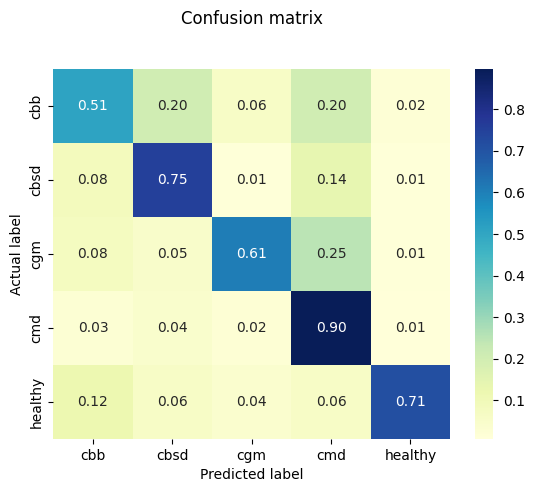

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
p = sns.heatmap(pd.DataFrame(cm), annot=True,xticklabels=target_names, yticklabels=target_names, cmap="YlGnBu" ,fmt='0.2f')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

#**Classification Report**

In [ ]:
#import classification_report
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred, target_names = target_names))

              precision    recall  f1-score   support

         cbb       0.43      0.51      0.47        49
        cbsd       0.82      0.75      0.78       166
         cgm       0.78      0.61      0.68        76
         cmd       0.80      0.90      0.85       250
     healthy       0.85      0.71      0.78        49

    accuracy                           0.77       590
   macro avg       0.74      0.70      0.71       590
weighted avg       0.78      0.77      0.77       590



#**Roc Curve**

In [ ]:
from sklearn.metrics import roc_curve, auc
from itertools import cycle

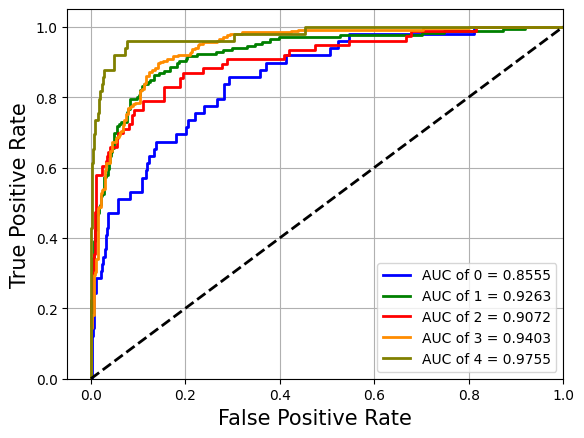

In [ ]:
fpr = dict()
tpr = dict()
roc_auc = dict()
lw=2
for i in range(5):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
colors =cycle(['blue', 'green', 'red','darkorange','olive'])
for i, color in zip(range(5), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='AUC of {0} = {1:0.4f}'
             ''.format(i, roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate',fontsize=15)
plt.ylabel('True Positive Rate',fontsize=15)
# plt.title('Receiver operating characteristic for multi-class data')
plt.legend(loc="lower right")
plt.grid()
plt.show()

#**Calculating the Flops and Size in MB**

In [ ]:
import tensorflow as tf
from tensorflow import keras

# Calculate FLOPs and MACs
flops = 0
macs = 0

for layer in model.layers:
    if isinstance(layer, keras.layers.Conv2D):
        # Get layer parameters
        filters = layer.filters
        kernel_size = layer.kernel_size
        strides = layer.strides
        input_shape = layer.input_shape[1:]

        # Calculate FLOPs
        flops += 2 * np.prod(input_shape) * filters * np.prod(kernel_size) / np.prod(strides)

        # Calculate MACs
        macs += np.prod(input_shape) * filters * np.prod(kernel_size) / np.prod(strides)

    elif isinstance(layer, keras.layers.Dense):
        # Get layer parameters
        units = layer.units
        input_shape = layer.input_shape[1:]

        # Calculate FLOPs
        flops += 2 * np.prod(input_shape) * units

        # Calculate MACs
        macs += np.prod(input_shape) * units

print("FLOPs:", flops)
print("MACs:", macs)

FLOPs: 9299364608.0
MACs: 4649682304.0


In [ ]:
# Convert FLOPs to GFLOPs
flops_in_giga = flops / 1e9

# Convert MACs to GMACs
macs_in_giga = macs / 1e9

print("GFLOPs:", flops_in_giga)
print("GMACs:", macs_in_giga)

GFLOPs: 9.299364608
GMACs: 4.649682304


In [ ]:
# Calculate model size in MB
model_size = model.count_params() * 4 / (1024 * 1024)  # Assuming float32 precision
print("Model Size (MB):", model_size)

Model Size (MB): 2.4734115600585938


#**Feature Visualization**

##**Saving the model Features**

In [ ]:
from keras.models import Model
model = model
layer_name = 'dense_3'
intermediate_layer_model = Model(inputs = model.input, outputs = model.get_layer(layer_name).output)
intermediate_output1 = intermediate_layer_model.predict([X_train])

166/166 [==============================] - 15s 90ms/step


In [ ]:
import numpy as np
import pandas as pd
np.save('demo1.npy', intermediate_output1)
j = np.load('demo1.npy')
np.savetxt("/content/drive/MyDrive/Casava_Proposed_Features.csv", j, delimiter = ",")

##**Loading and applying TSNE on Model features**

###**Original data distribution**

In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/RASHI/CASAVA/Casava_X_train.csv", header = None, delimiter = ",")
df

In [ ]:
import numpy as np
from sklearn.manifold import TSNE
X = np.array(df)
X_embedded = TSNE(n_components=2).fit_transform(X)

In [ ]:
df1 = pd.read_csv("/content/drive/MyDrive/RASHI/CASAVA/Casava_y_train.csv", header = None,  delimiter = ",")
df1.head()

In [ ]:
import plotly.express as px
fig = px.scatter(X_embedded, x =0, y = 1, color=df1[0], width=600, height=500)
fig.show()

###**Model Feature Distribution**

In [ ]:
df2 = pd.read_csv("/content/drive/MyDrive/Casava_Proposed_Features.csv", header = None, delimiter = ",")
df2

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,0.0,0.000000,0.000000,0.756991,0.0,0.0,0.038552,0.000000,0.0,0.000000,...,0.000000,0.009144,0.292541,0.0,0.886696,0.358499,0.056165,0.674269,0.0,0.483526
1,0.0,0.000000,0.000000,0.540630,0.0,0.0,1.326695,0.000000,0.0,0.000000,...,0.712977,0.332803,0.000000,0.0,3.472128,2.111000,0.696345,0.929333,0.0,0.965711
2,0.0,0.000000,0.000000,1.024111,0.0,0.0,0.000000,0.000000,0.0,0.201135,...,0.000000,0.000000,0.070935,0.0,0.164345,0.000000,0.000000,0.214924,0.0,0.011452
3,0.0,0.000000,0.276140,0.470702,0.0,0.0,0.000000,0.153340,0.0,0.340123,...,0.000000,0.119710,0.216763,0.0,0.197765,0.541225,0.529352,0.179804,0.0,0.117962
4,0.0,0.418122,0.000000,0.343262,0.0,0.0,0.000000,0.013659,0.0,0.516264,...,0.000000,0.243031,0.330052,0.0,0.000000,0.306159,0.245223,0.008338,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5299,0.0,0.000000,0.481544,0.388659,0.0,0.0,0.069822,0.057804,0.0,0.434835,...,0.000000,0.258123,0.484364,0.0,0.000000,0.692561,0.445198,0.232264,0.0,0.512580
5300,0.0,0.000000,0.000000,1.607115,0.0,0.0,1.257443,0.000000,0.0,0.000000,...,0.591819,0.000000,0.725024,0.0,3.030274,0.207035,0.000000,1.550269,0.0,1.553226
5301,0.0,0.000000,0.000000,0.409176,0.0,0.0,0.000000,0.225659,0.0,0.397610,...,0.000000,0.000000,0.237417,0.0,0.000000,0.198254,0.337618,0.168129,0.0,0.007321
5302,0.0,0.000000,0.840915,0.000000,0.0,0.0,0.000000,0.448396,0.0,0.040734,...,0.151660,0.000000,0.000000,0.0,0.241615,1.180383,0.667499,0.295751,0.0,0.031207


In [ ]:
import numpy as np
from sklearn.manifold import TSNE
X1 = np.array(df2)
X_embedded1 = TSNE(n_components=2).fit_transform(X1)

In [ ]:
df1 = pd.read_csv("/content/drive/MyDrive/RASHI/CASAVA/Casava_y_train.csv", header = None,  delimiter = ",")
df1.head()

,0
0,3.0
1,1.0
2,0.0
3,0.0
4,4.0


In [ ]:
import plotly.express as px
fig = px.scatter(X_embedded1,x =0, y = 1, color=df1[0], width=600, height=500)
fig.show()

#**Grad_Cam_Visualization**

In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 17.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283839 sha256=10829d1bb3e69b37bd4e448d0eb7592104e4b18c2dd83adf7cb1983030263ab4
  Stored in directory: /root/.cache/pip/wheels/fd/a2/af/9ac0a1a85a27f314a06b39e1f492bee1547d52549a4606ed89
Successfully built lime


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 [==============================] - 0s 20ms/step


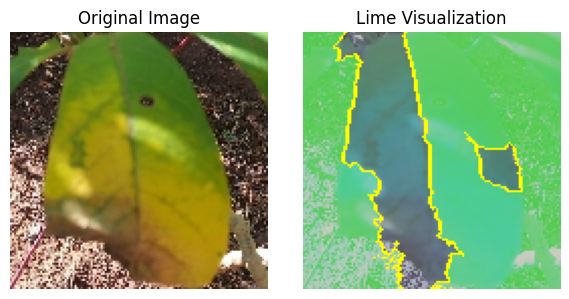

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.imagenet_utils import preprocess_input
from lime import lime_image
from skimage.segmentation import mark_boundaries


# Load and preprocess the input image
image_path = '/content/drive/MyDrive/RASHI/Test_Attentions/CASAVA/0/train-cbb-139.jpg'
img = load_img(image_path, target_size=(128, 128))
x = img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)


# Function to preprocess the image for Lime
def lime_preprocess(x):
    x = x / 255.0  # Normalize pixel values
    return x

# Create Lime explainer and generate explanations
explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(lime_preprocess(x)[0], model.predict, top_labels=1, hide_color=0, num_samples=1000)

# Retrieve the explanation image and mask
temp, mask = explanation.get_image_and_mask(explanation.top_labels[0], positive_only=False, num_features=5, hide_rest=False)

# Overlay the mask on the original image
img_with_mask = mark_boundaries(temp / 2 + 0.5, mask)

# Plot the original image and the image with the Lime mask
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(img)
ax[0].set_title('Original Image')
ax[0].axis('off')
ax[1].imshow(img_with_mask)
ax[1].set_title('Lime Visualization')
ax[1].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras

# Display
from IPython.display import Image, display
import matplotlib.pyplot as plt
import matplotlib.cm as cm

In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # First, we create a model that maps the input image to the activations
    # of the last conv layer as well as the output predictions
    grad_model = keras.models.Model(
        model.inputs, [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Then, we compute the gradient of the top predicted class for our input image
    # with respect to the activations of the last conv layer
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # This is the gradient of the output neuron (top predicted or chosen)
    # with regard to the output feature map of the last conv layer
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # This is a vector where each entry is the mean intensity of the gradient
    # over a specific feature map channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # We multiply each channel in the feature map array
    # by "how important this channel is" with regard to the top predicted class
    # then sum all the channels to obtain the heatmap class activation
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # For visualization purpose, we will also normalize the heatmap between 0 & 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

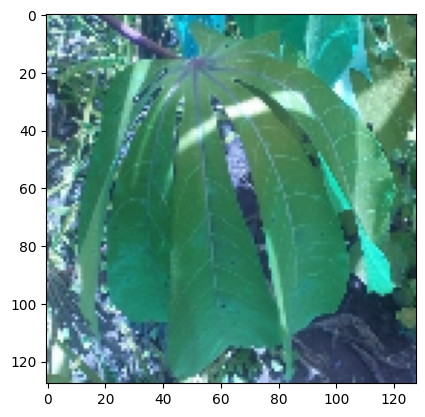

In [ ]:
plt.imshow(X_test[8])

In [ ]:
x.shape

(128, 128, 3)

1/1 [==============================] - 0s 20ms/step
Predicted: [1]


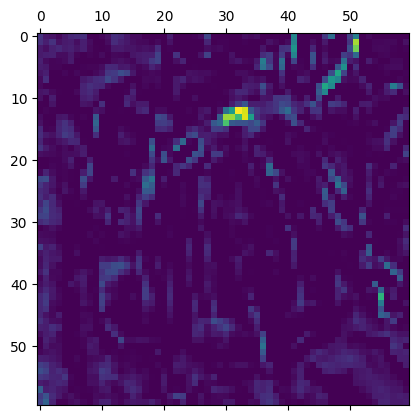

In [ ]:
# Load and preprocess the input image
from tensorflow.keras.applications.imagenet_utils import preprocess_input
# x = X_test[7]
# x = np.expand_dims(x, axis = 0)
# x = preprocess_input(X_test[7])
x = np.expand_dims(X_test[8], axis = 0)


# Make model
# import keras
# model = keras.models.load_model('/content/drive/MyDrive/RASHI/best_Plant_weights.h5')

# Remove last layer's softmax
model.layers[-1].activation = None

# decode_predictions = model.decode(preprocessed_input)
# Print what the top predicted class is
preds = model.predict(x)
print("Predicted:", np.argmax(preds, axis = 1))

last_conv_layer_name = 'conv2d_11'

# Generate class activation heatmap
heatmap = make_gradcam_heatmap(x, model, last_conv_layer_name)

# Display heatmap
plt.matshow(heatmap)
plt.show()

In [ ]:
def save_and_display_gradcam(img, heatmap, cam_path="cam.jpg", alpha=0.4):
    # Load the original image
    # img = keras.utils.load_img(img_path)
    # img = keras.utils.img_to_array(img)

    # Rescale heatmap to a range 0-255
    heatmap = np.uint8(255 * heatmap)

    # Use jet colormap to colorize heatmap
    jet = cm.get_cmap("jet")

    # Use RGB values of the colormap
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    # Create an image with RGB colorized heatmap
    jet_heatmap = keras.utils.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = keras.utils.img_to_array(jet_heatmap)

    # Superimpose the heatmap on original image
    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = keras.utils.array_to_img(superimposed_img)

    # Save the superimposed image
    superimposed_img.save(cam_path)

    # Display Grad CAM
    display(Image(cam_path))


save_and_display_gradcam(X_test[8], heatmap)

NameError: ignored